# MAR/MARX Monte Carlo Simulations

Artificial time series are generated using known parameter values. The model parameters are then estimated using AML Estimation

The experiment has two main objectives:

1. Evaluate the accuracy of MLE parameter estimates.
2. Compare the bimodality measure with explosive episodes identified by the PSY procedure.

The same simulated time series are used throughout the experiment to ensure that the estimation, predictive density, and PSY analyses are directly comparable.

## 1. Define parameters and relevant functions for MC simulations and MLE estimation. 

Six data-generating processes are considered:

1. MAR(0,1) with Cauchy innovations.
2. MAR(0,1) with Student-t innovations.
3. MAR(1,1) with Cauchy innovations.
4. MAR(1,1) with Student-t innovations.
5. MARX(1,1,1) with Cauchy innovations.
6. MARX(1,1,1) with Student-t innovations.

The true parameter values are known, allowing the estimated parameters to be compared with their corresponding true values. 
MLE is performed using a multi-start optimisation procedure to reduce the risk of obtaining a poor local solution.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from scipy.special import gammaln
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from pathlib import Path
import importlib.util

In [ ]:
T = 400
BURN = 25
N_REPLICATIONS = 500
SEED = 42
OUTPUT_DIR = Path('mle_only_results')

DESIGNS = [
    dict(name='MAR01_Cauchy', order=0, dist='cauchy', phi=0., psi=.8, beta=0., sigma=1., nu=np.nan),
    dict(name='MAR01_StudentT', order=0, dist='student', phi=0., psi=.8, beta=0., sigma=1., nu=3.),
    dict(name='MAR11_Cauchy', order=1, dist='cauchy', phi=.3, psi=.7, beta=0., sigma=1., nu=np.nan),
    dict(name='MAR11_StudentT', order=1, dist='student', phi=.3, psi=.7, beta=0., sigma=1., nu=3.),
    dict(name='MARX111_Cauchy', order=1, dist='cauchy', phi=.3, psi=.7, beta=.6, sigma=1., nu=np.nan),
    dict(name='MARX111_StudentT', order=1, dist='student', phi=.3, psi=.7, beta=.6, sigma=1., nu=3.),
]

### Simulate MAR/MARX processes
def simulate(design, rng, T=T, burn=BURN):
    """Simulate (1-phi L)(1-psi L^-1)y_t = beta*x_t + epsilon_t."""
    n = T + 2 * burn
    x = rng.normal(size=n) if design['beta'] != 0 else np.zeros(n)
    if design['dist'] == 'cauchy':
        eps = design['sigma'] * rng.standard_cauchy(n)
    else:
        eps = design['sigma'] * rng.standard_t(design['nu'], n)
    z = design['beta'] * x + eps
    u = np.empty(n)
    u[-1] = z[-1]
    for i in range(n - 2, -1, -1):
        u[i] = z[i] + design['psi'] * u[i + 1]
    y = np.empty(n)
    y[0] = u[0]
    for i in range(1, n):
        y[i] = u[i] + design['phi'] * y[i - 1]
    sl = slice(burn, burn + T)
    return y[sl], x[sl]

### Define parameter names
def parameter_names(design):
    names = ['phi'] if design['order'] == 1 else []
    names.append('psi')
    if design['beta'] != 0:
        names.append('beta')
    names.append('sigma')
    if design['dist'] == 'student':
        names.append('nu')
    return names

### Define innovation log-density function
def innovation_logpdf(e, sigma, dist, nu):
    if dist == 'cauchy':
        return -np.log(np.pi * sigma) - np.log1p((e / sigma)**2)
    constant = (gammaln((nu + 1) / 2) - gammaln(nu / 2)
                - 0.5 * np.log(nu * np.pi) - np.log(sigma))
    return constant - (nu + 1) / 2 * np.log1p((e / sigma)**2 / nu)

### Define negative log-likelihood function
def negative_loglik(theta, y, x, design):
    p = dict(zip(parameter_names(design), theta))
    phi, psi = p.get('phi', 0.), p['psi']
    beta, sigma, nu = p.get('beta', 0.), p['sigma'], p.get('nu', np.nan)
    if design['order'] == 0:
        residuals = y[:-1] - psi * y[1:] - beta * x[:-1]
    else:
        residuals = ((1 + phi * psi) * y[1:-1]
                     - phi * y[:-2] - psi * y[2:] - beta * x[1:-1])
    if not np.all(np.isfinite(residuals)):
        return 1e100
    logp = innovation_logpdf(residuals, sigma, design['dist'], nu)
    return float(-np.sum(logp)) if np.all(np.isfinite(logp)) else 1e100

### Estimate MLE with bounded multi-start MLE
def estimate_mle(y, x, design, n_starts=3, rng=None):
    rng = np.random.default_rng() if rng is None else rng
    names = parameter_names(design)
    initial = dict(phi=.2, psi=.5, beta=.2, sigma=1., nu=4.)
    limits = dict(phi=(-.98, .98), psi=(-.98, .98), beta=(-5., 5.),
                  sigma=(.05, 30.), nu=(0.1, 40.))
    bounds = [limits[name] for name in names]
    candidates = [np.array([initial[name] for name in names], dtype=float)]
    for _ in range(n_starts - 1):
        proposal = []
        for name in names:
            if name in ('phi', 'psi'):
                proposal.append(rng.uniform(-.5, .9))
            elif name == 'beta':
                proposal.append(rng.uniform(-1., 1.))
            elif name == 'sigma':
                proposal.append(rng.uniform(.5, 2.))
            else:
                proposal.append(rng.uniform(2.5, 8.))
        candidates.append(np.asarray(proposal))
    results = [minimize(negative_loglik, x0, args=(y, x, design),
                        method='L-BFGS-B', bounds=bounds,
                        options={'maxiter': 500, 'ftol': 1e-9}) for x0 in candidates]
    good = [r for r in results if r.success and np.isfinite(r.fun)]
    selected = min(good if good else results, key=lambda r: r.fun if np.isfinite(r.fun) else np.inf)
    return selected, dict(zip(names, selected.x))


In [ ]:
### Run Monte Carlo simulations and estimate MLE
def run_monte_carlo(n_replications=N_REPLICATIONS, seed=SEED, n_starts=3,
                    T=T, burn=BURN, save=True):
    records = []
    simulated = {}  
    seeds = np.random.SeedSequence(seed).spawn(len(DESIGNS) * n_replications)
    for j, design in enumerate(DESIGNS):
        for rep in range(n_replications):
            rng = np.random.default_rng(seeds[j * n_replications + rep])
            y, x = simulate(design, rng, T=T, burn=burn)
            simulated[(design['name'], rep + 1)] = (y.copy(), x.copy())
            result, fitted = estimate_mle(y, x, design, n_starts=n_starts, rng=rng)
            row = {'design': design['name'], 'replication': rep + 1,
                   'converged': bool(result.success and np.isfinite(result.fun)),
                   'negative_loglikelihood': float(result.fun)}
            for name in parameter_names(design):
                row[f'{name}_true'] = design[name]
                row[f'{name}_hat'] = fitted[name]
                row[f'{name}_error'] = fitted[name] - design[name]
            records.append(row)
        print(f"Completed {design['name']}: {n_replications} replications", flush=True)

    estimates = pd.DataFrame(records)
    summary_rows = []
    for design in DESIGNS:
        subset = estimates[estimates['design'] == design['name']]
        success = subset[subset['converged']]
        for name in parameter_names(design):
            errors = success[f'{name}_error'].dropna().to_numpy()
            n = len(errors)
            bias = float(np.mean(errors)) if n else np.nan
            sd = float(np.std(errors, ddof=1)) if n > 1 else np.nan
            mc_se = sd / np.sqrt(n) if n > 1 else np.nan
            summary_rows.append({
                'design': design['name'], 'parameter': name,
                'true_value': design[name], 'replications': len(subset),
                'successful_replications': n,
                'convergence_rate': len(success) / len(subset),
                'mean_estimate': float(np.mean(success[f'{name}_hat'])) if n else np.nan,
                'bias': bias,
                'std_dev': sd,
                'rmse': float(np.sqrt(np.mean(errors**2))) if n else np.nan,
                'mc_se_of_bias': mc_se,
                'bias_ci_95_low': bias - 1.96 * mc_se,
                'bias_ci_95_high': bias + 1.96 * mc_se
            })
    summary = pd.DataFrame(summary_rows)
    if save:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        estimates.to_csv(OUTPUT_DIR / 'mle_replications.csv', index=False)
        summary.to_csv(OUTPUT_DIR / 'mle_bias_summary.csv', index=False)
        np.savez_compressed(
            OUTPUT_DIR / 'simulated_series.npz',
            **{f"{name}__rep{rep:04d}__{which}": values
               for (name,rep),(yy,xx) in simulated.items()
               for which,values in [('y',yy),('x',xx)]}
        )
    return estimates, summary


## 2. Simulate MAR/MARX processes and perform AML Estimation

Generate and estimate the 500 Monte Carlo series per design. Both MLE estimates and the actual simulated paths are saved.

**Note**: The MLE cell generates each series **once** and saves those exact `y` and `x` arrays to `mle_only_results/simulated_series.npz`. Later PSY and bimodality cells **only load these saved series and estimated parameters**.


In [ ]:
estimates, summary = run_monte_carlo(n_replications=500, seed=42, n_starts=3, T=400, burn=25) #n_starts is the number of points for the multi-start optimisation

estimates = pd.read_csv(OUTPUT_DIR / 'mle_replications.csv')
summary = pd.read_csv(OUTPUT_DIR / 'mle_bias_summary.csv')
display(summary)

,design,parameter,true_value,replications,successful_replications,convergence_rate,mean_estimate,bias,std_dev,rmse,mc_se_of_bias,bias_ci_95_low,bias_ci_95_high
0,MAR01_Cauchy,psi,0.8,500,500,1.0,0.800066,0.000066,0.002524,0.002522,0.000113,-0.000155,0.000288
1,MAR01_Cauchy,sigma,1.0,500,500,1.0,0.998547,-0.001453,0.069712,0.069657,0.003118,-0.007563,0.004658
2,MAR01_StudentT,psi,0.8,500,500,1.0,0.796529,-0.003471,0.023126,0.023362,0.001034,-0.005498,-0.001444
3,MAR01_StudentT,sigma,1.0,500,500,1.0,1.002127,0.002127,0.068062,0.068027,0.003044,-0.003838,0.008093
4,MAR01_StudentT,nu,3.0,500,500,1.0,3.129412,0.129412,0.655400,0.667411,0.029310,0.071963,0.186860
5,MAR11_Cauchy,phi,0.3,500,500,1.0,0.300254,0.000254,0.004436,0.004439,0.000198,-0.000135,0.000643
6,MAR11_Cauchy,psi,0.7,500,500,1.0,0.700025,0.000025,0.003451,0.003448,0.000154,-0.000278,0.000327
7,MAR11_Cauchy,sigma,1.0,500,500,1.0,0.996100,-0.003900,0.074327,0.074355,0.003324,-0.010415,0.002615
8,MAR11_StudentT,phi,0.3,500,500,1.0,0.299591,-0.000409,0.042150,0.042110,0.001885,-0.004103,0.003286
9,MAR11_StudentT,psi,0.7,500,500,1.0,0.698263,-0.001737,0.031847,0.031863,0.001424,-0.004529,0.001054


## 3. Define Predictive Density Functions

In [ ]:
def student_t_pdf(e, nu, sigma):
    e = np.asarray(e, dtype=float)
    return np.exp(gammaln((nu + 1)/2) - gammaln(nu/2) - .5*np.log(nu*np.pi) - np.log(sigma)
                  - (nu+1)/2 * np.log1p((e/sigma)**2/nu))

def predictive_density_mar01_cauchy(t0, y_next, y, psi, sigma):
    
    
    # last observed value
    yT = y[t0]

    term1 = 1.0 / (np.pi * sigma)
    term2 = sigma**2 / ((yT - psi * y_next)**2 + sigma**2)
    term3 = (sigma**2 + (1 - abs(psi))**2 * yT**2) / (
        sigma**2 + (1 - abs(psi))**2 * y_next**2
    )
    return term1 * term2 * term3

def sample_based_pred_density_mar01(t0, y_next, y, psi, sigma, nu):
    y = np.asarray(y)


    yT = y[t0]

    # Historical observations available up to t0
    y_sample = y[:t0+1]

    denom = np.sum(student_t_pdf(yT - psi * y_sample, nu, sigma))
    denom = max(denom, 1e-12)

    dens = np.empty_like(y_next, dtype=float)
    for i, x in enumerate(y_next):
        numer = np.sum(student_t_pdf(x - psi * y_sample, nu, sigma))
        dens[i] = student_t_pdf(yT - psi * x, nu, sigma) * numer / denom

    return dens

def predictive_density_mar11_cauchy(t0, y_next, y, phi, psi, sigma):

    y = np.asarray(y, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    y_T = y[t0]
    y_Tm1 = y[t0-1]
 
    # compute u_T (u_T = y_T - phi * y_{T-1})
    u_T = y_T - phi * y_Tm1

    # compute u_{T+1}: z = y_{T+1} - phi * y_{T}
    z = y_next - phi * y_T

    term1 = 1.0 / (np.pi * sigma)
    term2 = sigma**2 / ((u_T - psi * z)**2 + sigma**2)
    term3 = (sigma**2 + (1 - abs(psi))**2 * u_T**2) / (
        sigma**2 + (1 - abs(psi))**2 * z**2
    )

    density = term1 * term2 * term3

    return density


def sample_based_pred_density_mar11(t0,y_next,y,phi,psi,sigma,nu,):

    y = np.asarray(y, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    y_T = y[t0]
    y_Tm1 = y[t0-1]

    # current state u_T
    u_T = y_T - phi * y_Tm1

    # sample of past states u_t = y_t - phi y_{t-1}, for t = 1,...,T-1 (in 0-based indexing)
    u_sample = y[1:t0+1] - phi * y[:t0]

    # candidate future state
    u_next = y_next - phi * y_T

    # first factor: g(u_T - psi*u_{T+1})
    term1 = student_t_pdf(u_T - psi * u_next, nu, sigma)

    # numerator: sum_t g(u_{T+1} - psi*u_t)
    num = np.sum(student_t_pdf(u_next[:, None] - psi * u_sample[None, :], nu, sigma), axis=1 )

    # denominator: sum_t g(u_T - psi*u_t)
    den = np.sum(student_t_pdf(u_T - psi * u_sample, nu, sigma))
    den = max(den, 1e-12)

    dens = term1 * (num / den)

    return dens
    
def predictive_density_marx111_cauchy(t0, y_next, y, X,
                                        phi, psi, beta, sigma):

    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)
    beta = np.atleast_1d(np.asarray(beta, dtype=float))

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    if len(X) != len(y):
        raise ValueError("X and y must have the same number of rows.")
    if X.shape[1] != len(beta):
        raise ValueError("beta must match the number of columns in X.")
    if not (1 <= t0 < len(y)):
        raise ValueError("t0 must satisfy 1 <= t0 < len(y).")
    if abs(psi) >= 1:
        raise ValueError("|psi| must be less than 1.")
    if sigma <= 0:
        raise ValueError("sigma must be positive.")

    T = len(y) - 1

    # Observed values at t0
    y_T = y[t0]
    y_Tm1 = y[t0 - 1]

    # Compute u_t
    u_T = y_T - phi * y_Tm1

    # Candidate u_{t+1}
    z = y_next - phi * y_T

    # Exogenous contribution beta'X_t
    bX = X @ beta

    # --------------------------------------
    # EXOGENOUS SUMS
    # --------------------------------------

    if t0 < T:
        # IN-SAMPLE:
        # Use realised X values only, up to T.
        # Truncate the sums at T.

        m_t = sum(
            psi**j * bX[t0 + j]
            for j in range(T - t0 + 1)
        )

        m_tp1 = sum(
            psi**j * bX[t0 + 1 + j]
            for j in range(T - t0)
        )

    else:
        # OUT-OF-SAMPLE:
        # Assume X[T+j] = 0 for all j >= 1.
        # Keep actual observed X[T].

        m_t = bX[T]
        m_tp1 = 0.0

    # --------------------------------------
    # CAUCHY PREDICTIVE DENSITY
    # --------------------------------------

    # First term: Cauchy normalization
    term1 = 1.0 / (np.pi * sigma)

    # Second term: innovation density
    term2 = sigma**2 / (
        (u_T - psi * z - bX[t0])**2 + sigma**2
    )

    # Third term: conditional marginal-density ratio
    a = (1.0 - abs(psi))**2

    term3 = (
        sigma**2 + a * (u_T - m_t)**2
    ) / (
        sigma**2 + a * (z - m_tp1)**2
    )

    density = term1 * term2 * term3

    return density


def sample_based_pred_density_marx11(
    t0, y_next, y, X, phi, psi, beta, sigma, nu
):
    y = np.asarray(y, dtype=float)
    X = np.asarray(X, dtype=float)
    y_next = np.asarray(y_next, dtype=float)

    # Current and next exogenous observations
    x_T = X[t0]
    x_next = X[t0 + 1] if t0 + 1 < len(X) else 0.0

    # Current state
    y_T = y[t0]
    y_Tm1 = y[t0 - 1]
    u_T = y_T - phi * y_Tm1

    # Historical states
    u_sample = y[1:t0+1] - phi * y[:t0]

    # Candidate future state
    u_next = y_next - phi * y_T

    # First factor
    term1 = student_t_pdf(
        u_T - psi * u_next - beta * x_T,
        nu, sigma
    )

    # Numerator
    num = np.sum(
        student_t_pdf(
            u_next[:, None]
            - psi * u_sample[None, :]
            - beta * x_next,
            nu, sigma
        ),
        axis=1
    )

    # Denominator
    den = np.sum(
        student_t_pdf(
            u_T - psi * u_sample - beta * x_T,
            nu, sigma
        )
    )
    den = max(den, 1e-12)

    return term1 * (num / den)

## 4. Load the MLE simulations and estimates (no new draws)

In [ ]:
DATA_DIR = OUTPUT_DIR
sim_path = DATA_DIR / 'simulated_series.npz'
if not sim_path.exists():
    raise FileNotFoundError(f"{sim_path} not found. Run the MLE simulation cell once first.")

saved_simulations = np.load(sim_path, allow_pickle=False)
estimates = pd.read_csv(DATA_DIR / 'mle_replications.csv')
summary = pd.read_csv(DATA_DIR / 'mle_bias_rmse_summary.csv')

def get_saved_simulation(design_name, replication):
    prefix = f"{design_name}__rep{replication:04d}"
    return (saved_simulations[f"{prefix}__y"], saved_simulations[f"{prefix}__x"])

print('Saved Monte Carlo paths:', len(saved_simulations.files) // 2)
print('MLE estimates:', len(estimates))
display(summary)


Saved Monte Carlo paths: 3000
MLE estimates: 3000


,design,parameter,true_value,replications,successful_replications,convergence_rate,mean_estimate,bias,std_dev,rmse,mc_se_of_bias,bias_ci_95_low,bias_ci_95_high
0,MAR01_Cauchy,psi,0.8,500,500,1.0,0.800066,0.000066,0.002524,0.002522,0.000113,-0.000155,0.000288
1,MAR01_Cauchy,sigma,1.0,500,500,1.0,0.998547,-0.001453,0.069712,0.069657,0.003118,-0.007563,0.004658
2,MAR01_StudentT,psi,0.8,500,500,1.0,0.796529,-0.003471,0.023126,0.023362,0.001034,-0.005498,-0.001444
3,MAR01_StudentT,sigma,1.0,500,500,1.0,1.002127,0.002127,0.068062,0.068027,0.003044,-0.003838,0.008093
4,MAR01_StudentT,nu,3.0,500,500,1.0,3.129412,0.129412,0.655400,0.667411,0.029310,0.071963,0.186860
5,MAR11_Cauchy,phi,0.3,500,500,1.0,0.300254,0.000254,0.004436,0.004439,0.000198,-0.000135,0.000643
6,MAR11_Cauchy,psi,0.7,500,500,1.0,0.700025,0.000025,0.003451,0.003448,0.000154,-0.000278,0.000327
7,MAR11_Cauchy,sigma,1.0,500,500,1.0,0.996100,-0.003900,0.074327,0.074355,0.003324,-0.010415,0.002615
8,MAR11_StudentT,phi,0.3,500,500,1.0,0.299591,-0.000409,0.042150,0.042110,0.001885,-0.004103,0.003286
9,MAR11_StudentT,psi,0.7,500,500,1.0,0.698263,-0.001737,0.031847,0.031863,0.001424,-0.004529,0.001054


## 4. Define PSY and bimodality functions, as well as functions for PSY/Bimodality comparison

Load `PSY.py` module. Compare PSY episodes, not individual dates: an episode is matched if any eligible date has `B != 0` during the episode or within five observations before/after.

In [ ]:
# Define density functions for each design
def density_for_design(design, t0, grid, y, x, params):
    phi = params.get('phi', 0.0)
    psi = params['psi']; sigma = params['sigma']
    if design['dist'] == 'cauchy':
        if design['order'] == 0:
            return predictive_density_mar01_cauchy(t0, grid, y, psi, sigma)
        if design['beta'] == 0:
            return predictive_density_mar11_cauchy(t0, grid, y, phi, psi, sigma)
        return predictive_density_marx111_cauchy(t0, grid, y, x, phi, psi, params['beta'], sigma)
    nu = params['nu']
    if design['order'] == 0:
        return sample_based_pred_density_mar01(t0, grid, y, psi, sigma, nu)
    if design['beta'] == 0:
        return sample_based_pred_density_mar11(t0, grid, y, phi, psi, sigma, nu)
    return sample_based_pred_density_marx11(t0, grid, y, x, phi, psi, params['beta'], sigma, nu)


# Define bimodality measure
def bimodality_measure(dens, grid, prominence_factor=0.01):
    dens = np.asarray(dens, dtype=float)
    grid = np.asarray(grid, dtype=float)

    if (
        dens.shape != grid.shape
        or len(grid) < 3
        or not np.all(np.isfinite(dens))
    ):
        return np.nan

    dens = np.maximum(dens, 0.0)

    area = np.trapezoid(dens, grid)

    if not np.isfinite(area) or area <= 0:
        return np.nan

    d = dens / area

    peaks, _ = find_peaks(
        d,
        prominence=prominence_factor * d.max()
    )

    B = 0.0

    if len(peaks) >= 2:
        p1, p2 = np.sort(
            peaks[np.argsort(d[peaks])[-2:]]
        )

        h1, h2 = d[p1], d[p2]
        valley = np.min(d[p1:p2 + 1])

        B = float(np.clip(
            min(h1, h2) / max(h1, h2)
            * (1.0 - valley / min(h1, h2)),
            0.0, 1.0
        ))

    return B



# Load PSY implementation
_psy_path = Path('PSY.py')
_spec = importlib.util.spec_from_file_location('psy_original_user', _psy_path)
_psy_module = importlib.util.module_from_spec(_spec)
_spec.loader.exec_module(_psy_module)
PSY = _psy_module.PSY
cvPSYwmboot = _psy_module.cvPSYwmboot

# Define PSY episodes
def psy_episode_ranges(indicator):
    """Inclusive (start, end) positions for each contiguous PSY bubble."""
    flags = np.asarray(indicator, dtype=bool)
    jumps = np.diff(np.r_[False, flags, False].astype(int))
    return list(zip(np.flatnonzero(jumps == 1),
                    np.flatnonzero(jumps == -1) - 1))


def compare_B_PSY(B, psy_indicator, window=5, evaluation_start=150):
    """Fraction of evaluable PSY episodes with at least one nonzero B.

    Each episode counts only once, regardless of the number of dates with B != 0.
    Eligible PSY episodes must overlap the evaluation region (finite B values).
    Separate matches for during episode and episode expanded by ±window.
    """
    B = np.asarray(B, dtype=float)
    psy = np.asarray(psy_indicator, dtype=float)
    if B.ndim != 1 or psy.shape != B.shape:
        raise ValueError('B and PSY must be 1-D arrays of equal length')
    if window < 0:
        raise ValueError('window must be >= 0')
    n = len(B)
    eligible = (np.arange(n) >= evaluation_start) & np.isfinite(B)
    positive_B = eligible & (B != 0)
    psy_positive = np.isfinite(psy) & (psy > 0)
    episodes_all = psy_episode_ranges(psy_positive)

    # Exclude episodes entirely outside the period when B is calculated.
    episodes = [(s, e) for s, e in episodes_all if eligible[s:e+1].any()]
    during_count = 0
    within_count = 0
    for s, e in episodes:
        during = positive_B[s:e+1].any()
        expanded = positive_B[max(0, s-window):min(n, e+window+1)].any()
        during_count += int(during)
        within_count += int(expanded)

    N = len(episodes)
    return {
        'n_PSY_episodes': N,
        'n_matched_during': during_count,
        'n_matched_pm5': within_count,
        'pct_PSY_episodes_with_B_during': 100 * during_count / N if N else np.nan,
        'pct_PSY_episodes_with_B_pm5': 100 * within_count / N if N else np.nan,
    }


In [13]:
def evaluate_saved_psy_B(
    designs=DESIGNS, start_B=150, window=5,
    alpha=0.95, nboot=199, n_grid=2000,
    max_reps=None, save=True,
    out_dir='joint_mc_results'
):
    if alpha not in (0.90, 0.95, 0.99):
        raise ValueError('alpha must be 0.90, 0.95, or 0.99')
    out = Path(out_dir)
    if save:
        out.mkdir(parents=True, exist_ok=True)
    records = []
    for d in designs:
        fit_rows = estimates[estimates['design'] == d['name']].sort_values('replication')
        if max_reps is not None:
            fit_rows = fit_rows.head(max_reps)
        for _, row in fit_rows.iterrows():
            r = int(row['replication'])
            result_row = {'design': d['name'], 'replication': r}
            if not bool(row['converged']):
                records.append({**result_row, 'status': 'MLE failed'})
                continue
            y, x = get_saved_simulation(d['name'], r)
            params = {k: float(row[f'{k}_hat']) for k in parameter_names(d)}
            T_local = len(y)
            try:
                swindow0 = int(np.floor(T_local * (.01 + 1.8 / np.sqrt(T_local))))
                IC = 2
                adflag = 6
                Tb = 12 * 2 + swindow0 - 1
                bsadf = PSY(y, swindow0=swindow0, IC=IC, adflag=adflag)
                cv = cvPSYwmboot(y, swindow0=swindow0, IC=IC, adflag=adflag,
                                 Tb=Tb, nboot=nboot)
                cv_alpha = float(cv[{.90:0, .95:1, .99:2}[alpha]])
                psy = np.where(np.isfinite(bsadf), (bsadf > cv_alpha).astype(float), np.nan)

                B = np.full(T_local, np.nan)
        
                grid_min = np.min(y) - 0.5 * (np.max(y) - np.min(y))
                grid_max = np.max(y) + 0.5 * (np.max(y) - np.min(y))
                grid = np.linspace(grid_min, grid_max, n_grid)
                for t in range(max(1, start_B), T_local - 1):
                    dens = density_for_design(d, t, grid, y, x, params)
                    B[t] = bimodality_measure(dens, grid)
                stats = compare_B_PSY(B, psy, window=window,
                                      evaluation_start=start_B)
                records.append({**result_row, 'status': 'ok',
                                'psy_cv': cv_alpha, 'psy_alpha': alpha,
                                'window': window, **stats})
                 #save only the first replication                
                if save and r == 1:
                    pd.DataFrame({'t': np.arange(T_local), 'y': y,
                                  'B': B, 'BSADF': bsadf,
                                  'PSY_bubble': psy}).to_csv(
                        out / f"{d['name']}_rep{r:04d}.csv", index=False)
            except Exception as exc:
                records.append({**result_row, 'status': f'error: {exc}'})
                print(f"Failed PSY/B for {d['name']} replication {r}: {exc}")
        print(f"PSY/B finished: {d['name']}", flush=True)
        if save:
            pd.DataFrame(records).to_csv(out / 'replication_metrics.csv', index=False)

    replication_metrics = pd.DataFrame(records)
    valid = replication_metrics[replication_metrics['status'] == 'ok']
    summary_rows = []
    for d in designs:
        group = valid[valid['design'] == d['name']]
        eligible = group[group['n_PSY_episodes'] > 0]
        episodes = int(group['n_PSY_episodes'].sum()) if len(group) else 0
        matched_0 = int(group['n_matched_during'].sum()) if len(group) else 0
        matched_5 = int(group['n_matched_pm5'].sum()) if len(group) else 0
        rec = {'design': d['name'], 'replications_ok': len(group),
               'replications_with_PSY': len(eligible),
               'total_PSY_episodes': episodes,
               'mean_during_pct': eligible['pct_PSY_episodes_with_B_during'].mean(),
               'sd_during_pct': eligible['pct_PSY_episodes_with_B_during'].std(),
               'median_during_pct': eligible['pct_PSY_episodes_with_B_during'].median(),
               'mean_pm5_pct': eligible['pct_PSY_episodes_with_B_pm5'].mean(),
               'sd_pm5_pct': eligible['pct_PSY_episodes_with_B_pm5'].std(),
               'median_pm5_pct': eligible['pct_PSY_episodes_with_B_pm5'].median(),
               'pooled_during_pct': 100 * matched_0 / episodes if episodes else np.nan,
               'pooled_pm5_pct': 100 * matched_5 / episodes if episodes else np.nan}
        summary_rows.append(rec)
    psy_summary = pd.DataFrame(summary_rows)
    if save:
        replication_metrics.to_csv(out / 'replication_metrics.csv', index=False)
        psy_summary.to_csv(out / 'psy_summary_by_design.csv', index=False)
    return replication_metrics, psy_summary


## 6. Run PSY/Bimodality comparison

**Note:** The PSY bootstrap for the 500 × 6 processes is computationally very expensive. So, only `max_reps=100` and `nboot=99` are used.


In [18]:
rep_metrics, psy_summary = evaluate_saved_psy_B(
    max_reps=100, nboot=99, start_B=150, window=5
)
display(rep_metrics.head())
display(psy_summary.round(2))

PSY/B finished: MAR01_Cauchy
PSY/B finished: MAR01_StudentT
PSY/B finished: MAR11_Cauchy
PSY/B finished: MAR11_StudentT
PSY/B finished: MARX111_Cauchy
PSY/B finished: MARX111_StudentT


,design,replication,status,psy_cv,psy_alpha,window,n_PSY_episodes,n_matched_during,n_matched_pm5,pct_PSY_episodes_with_B_during,pct_PSY_episodes_with_B_pm5
0,MAR01_Cauchy,1,ok,1.766233,0.95,5,3,3,3,100.0,100.0
1,MAR01_Cauchy,2,ok,2.189279,0.95,5,2,2,2,100.0,100.0
2,MAR01_Cauchy,3,ok,2.298087,0.95,5,2,2,2,100.0,100.0
3,MAR01_Cauchy,4,ok,1.775290,0.95,5,2,2,2,100.0,100.0
4,MAR01_Cauchy,5,ok,2.563484,0.95,5,2,2,2,100.0,100.0


,design,replications_ok,replications_with_PSY,total_PSY_episodes,mean_during_pct,sd_during_pct,median_during_pct,mean_pm5_pct,sd_pm5_pct,median_pm5_pct,pooled_during_pct,pooled_pm5_pct
0,MAR01_Cauchy,100,98,266,98.06,6.67,100.0,100.00,0.00,100.0,96.99,100.00
1,MAR01_StudentT,100,32,39,78.12,40.04,100.0,79.69,39.88,100.0,71.79,74.36
2,MAR11_Cauchy,100,94,232,97.75,11.72,100.0,99.29,6.88,100.0,96.98,99.14
3,MAR11_StudentT,100,25,26,92.00,27.69,100.0,92.00,27.69,100.0,92.31,92.31
4,MARX111_Cauchy,100,95,242,97.74,8.04,100.0,99.82,1.71,100.0,96.69,99.59
5,MARX111_StudentT,100,19,19,94.74,22.94,100.0,94.74,22.94,100.0,94.74,94.74


## Check PSY/Bimodality comparison results visually for first replication

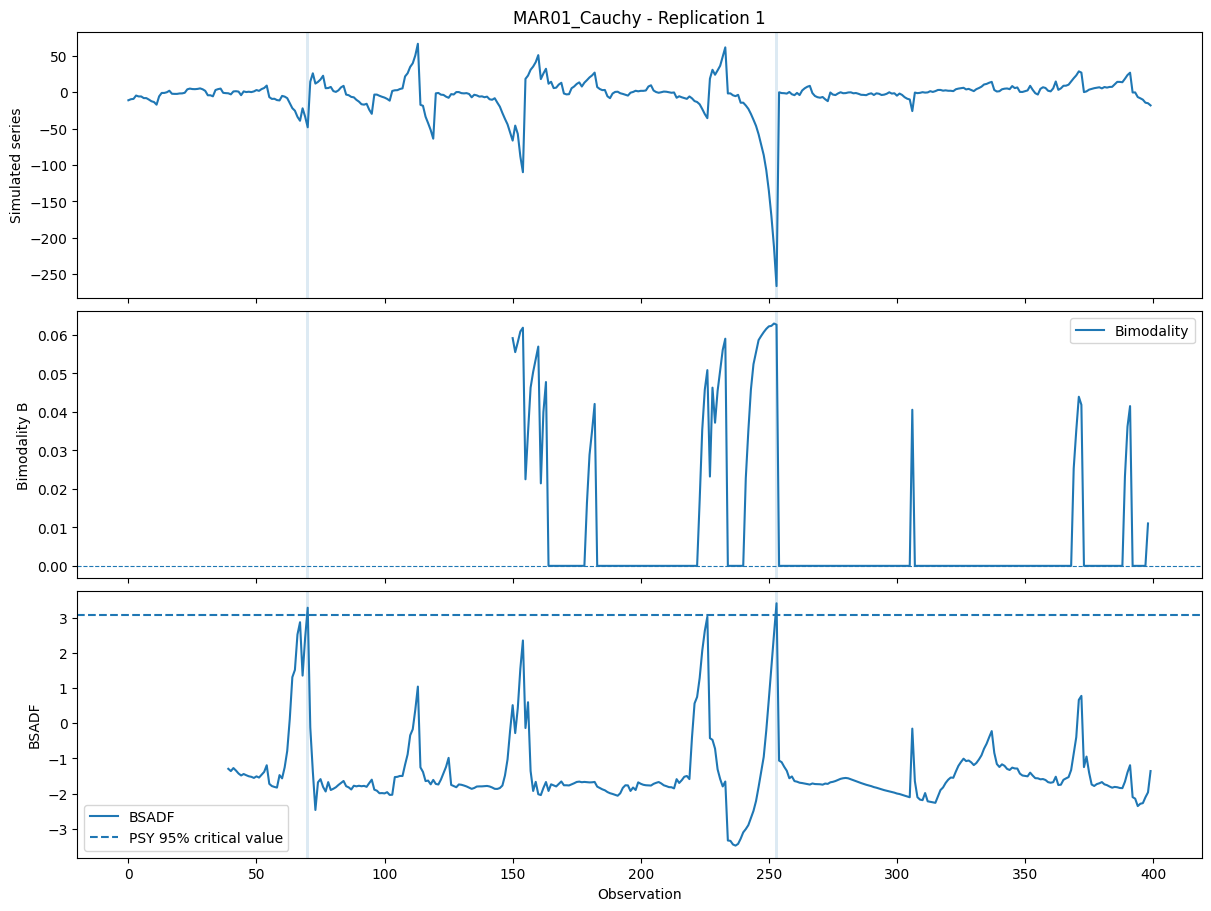

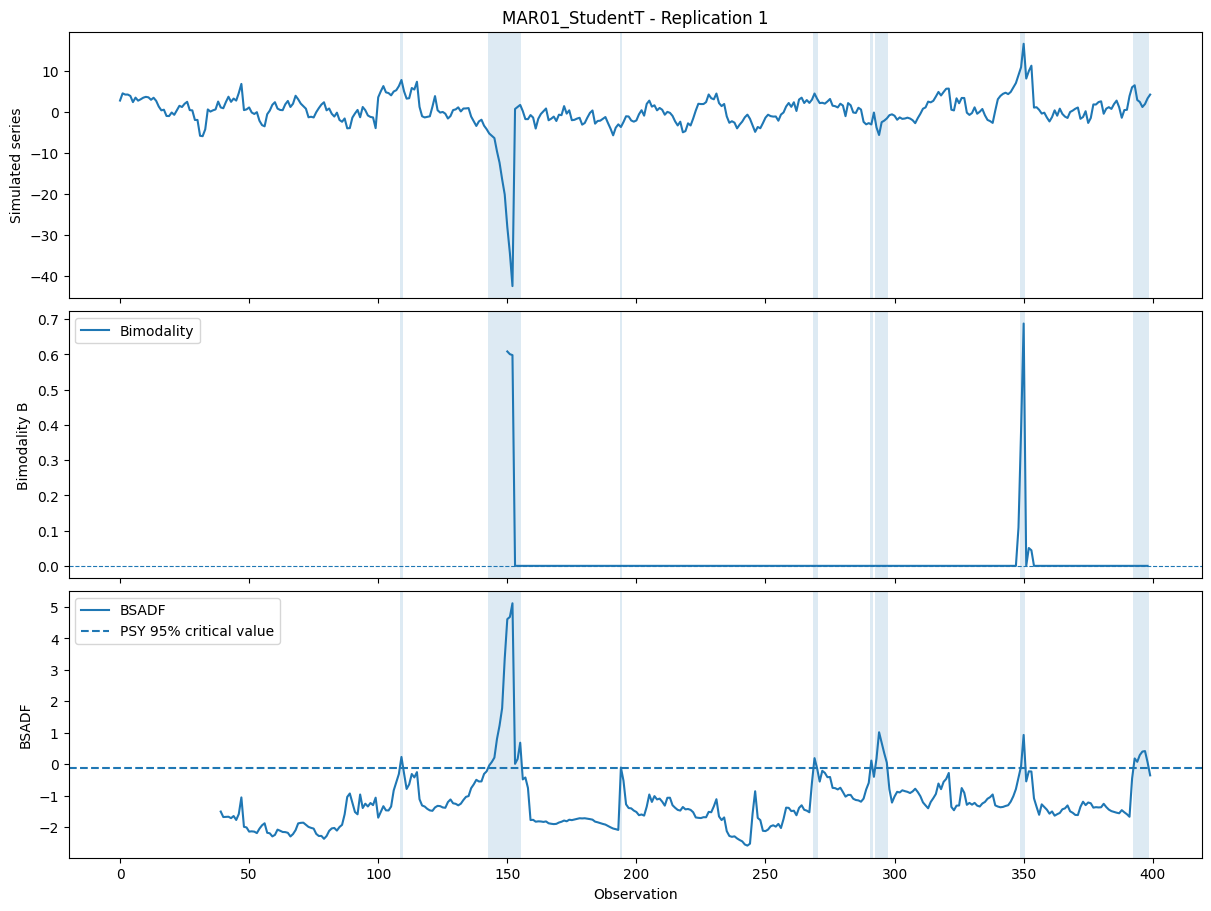

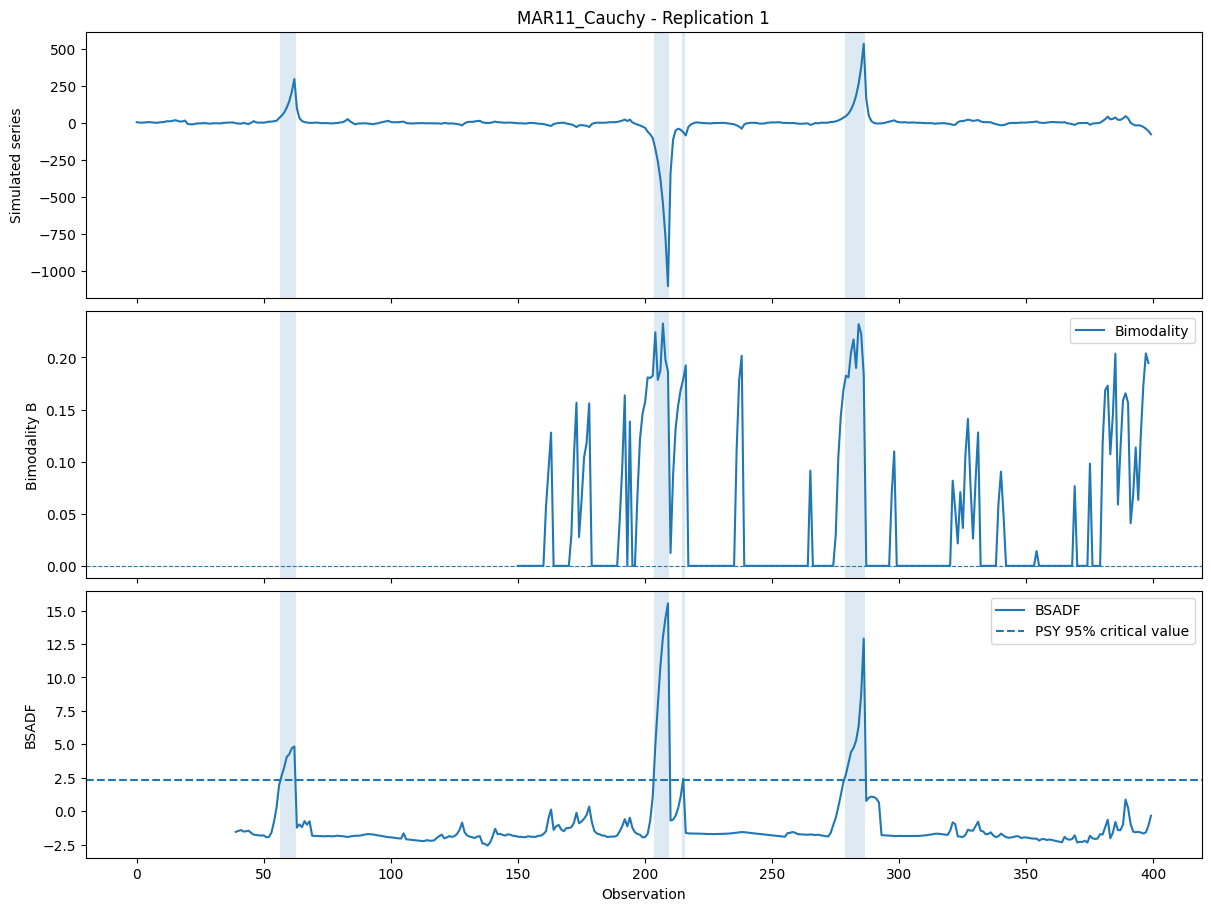

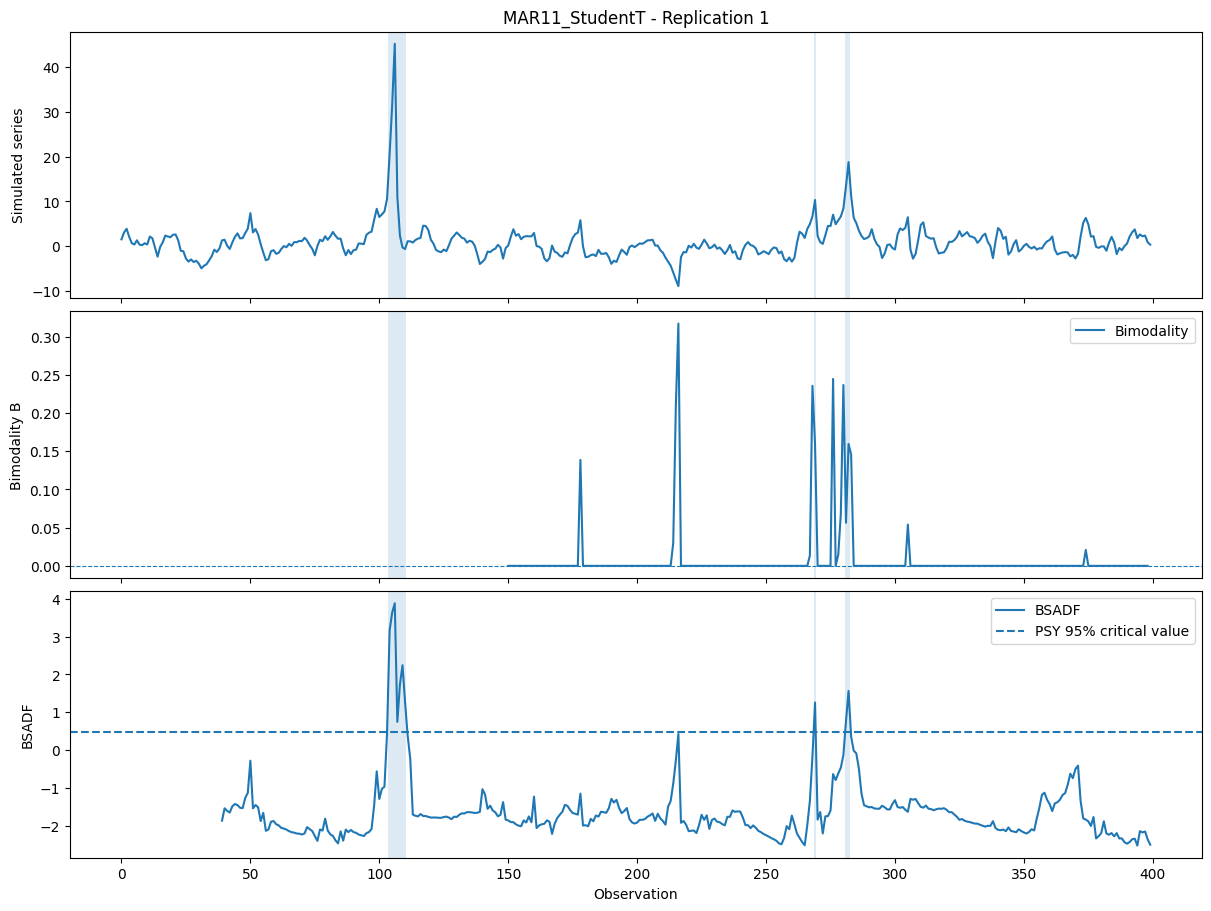

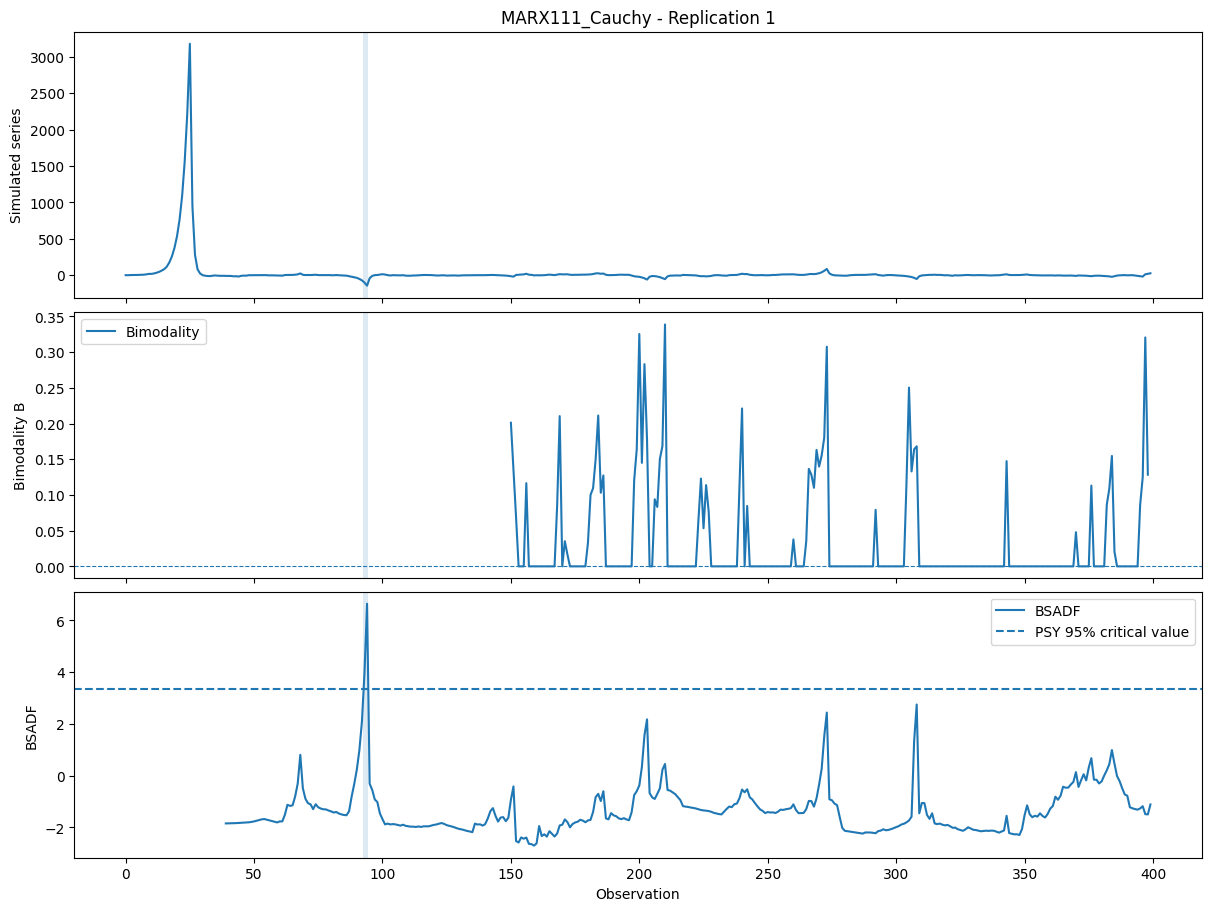

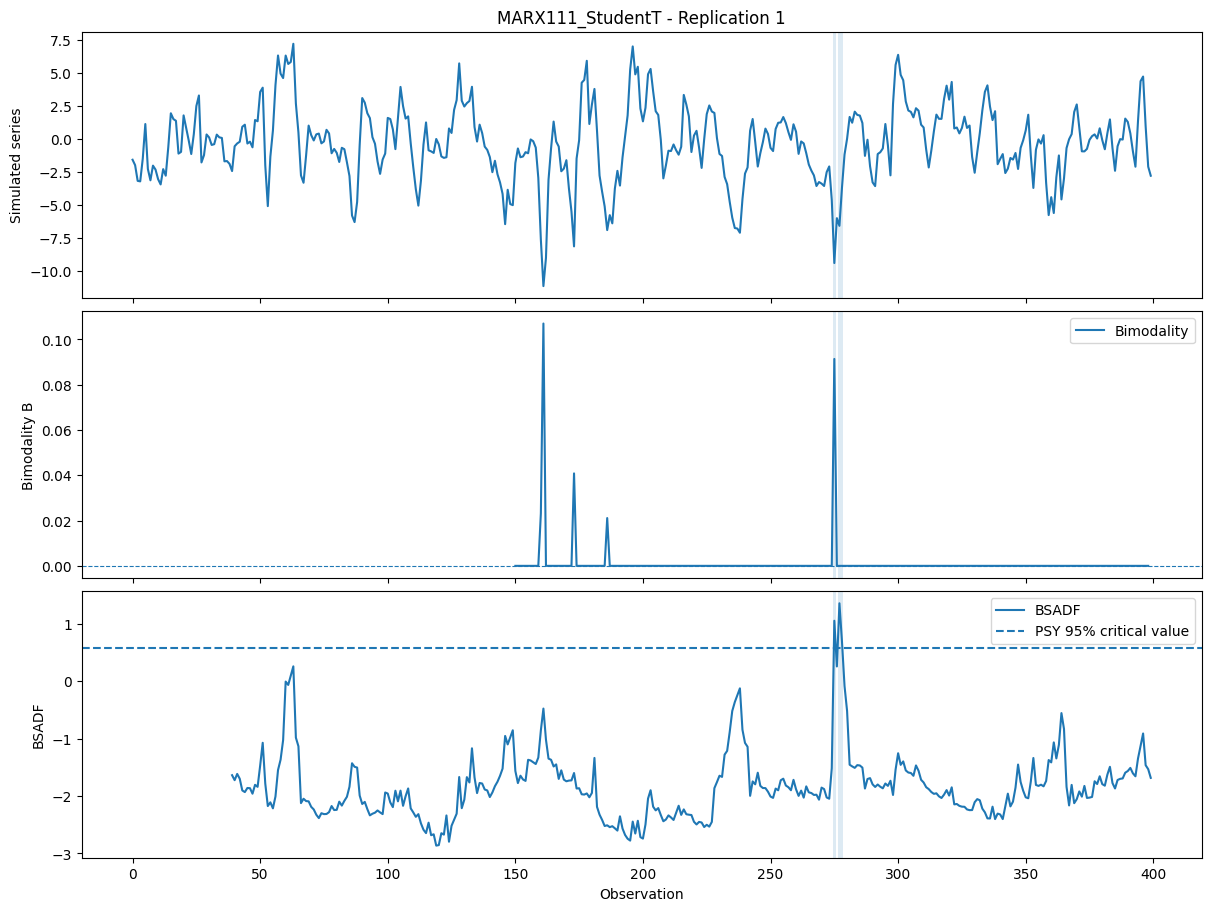

In [ ]:
result_dir = Path("joint_mc_results")

for design in DESIGNS:
    name = design["name"]

    file = result_dir / f"{name}_rep0001.csv"

    if not file.exists():
        print(f"Results not found: {file}")
        continue

    df = pd.read_csv(file)

    t = df["t"].to_numpy()
    y = df["y"].to_numpy()
    B = df["B"].to_numpy()
    bsadf = df["BSADF"].to_numpy()
    psy = df["PSY_bubble"].fillna(0).to_numpy() > 0

    row = rep_metrics[
        (rep_metrics["design"] == name) &
        (rep_metrics["replication"] == 1) &
        (rep_metrics["status"] == "ok")
    ]

    cv = float(row.iloc[0]["psy_cv"]) if not row.empty else np.nan

    fig, axes = plt.subplots(
        3, 1,
        figsize=(12, 9),
        sharex=True,
        constrained_layout=True
    )

    # Simulated series
    axes[0].plot(t, y)
    axes[0].set_ylabel("Simulated series")
    axes[0].set_title(f"{name} - Replication 1")

    # Bimodality
    axes[1].plot(t, B, label="Bimodality")
    axes[1].axhline(0, linestyle="--", linewidth=0.8)
    axes[1].set_ylabel("Bimodality B")
    axes[1].legend()

    # PSY / BSADF
    axes[2].plot(t, bsadf, label="BSADF")

    if np.isfinite(cv):
        axes[2].axhline(
            cv,
            linestyle="--",
            label="PSY 95% critical value"
        )

    axes[2].set_ylabel("BSADF")
    axes[2].set_xlabel("Observation")
    axes[2].legend()

    # Highlight PSY bubble episodes
    for start, end in psy_episode_ranges(psy):
        for ax in axes:
            ax.axvspan(
                t[start] - 0.5,
                t[end] + 0.5,
                alpha=0.15
            )

    plt.show()

